<a href="https://colab.research.google.com/github/Neethu-Teacher/Assignment-1/blob/main/Module_End_Assignment_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Import libraries and load dadaset**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Load the dataset
df = pd.read_csv("/content/customer_behavior.csv")

# Display the first five rows
print(df.head())

# Check column names and data types
print(df.info())

# Check for missing values
print(df.isnull().sum())

# Convert PurchaseAmount to numeric
df["PurchaseAmount"] = pd.to_numeric(
    df["PurchaseAmount"], errors="coerce")

# Remove rows with missing purchase amounts
df = df.dropna(subset=["PurchaseAmount"])

# Display summary statistics
print(df["PurchaseAmount"].describe())

   CustomerID  Gender Region  PurchaseAmount ProductCategory Churn  \
0        1001    Male  South          256.07         Fashion    No   
1        1002  Female  South             NaN     Electronics   Yes   
2        1003  Female   West         1194.41         Fashion    No   
3        1004  Female  South          413.06         Grocery    No   
4        1005    Male   West         1556.32         Fashion   Yes   

  CampaignGroup  
0             A  
1             B  
2             A  
3             A  
4             A  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerID       5000 non-null   int64  
 1   Gender           4903 non-null   object 
 2   Region           4825 non-null   object 
 3   PurchaseAmount   4850 non-null   float64
 4   ProductCategory  4474 non-null   object 
 5   Churn            4735 non-null   objec

**Question No:1**
*Average,Median and mode of Purchase Amount*

In [ ]:
import pandas as pd

#  Mean, median and mode
df = pd.read_csv("/content/customer_behavior.csv")
purchase = df["PurchaseAmount"]
mean_value = purchase.mean()
median_value = purchase.median()
mode_value = purchase.mode()
print("Average (Mean):", mean_value)
print("Median:", median_value)
print("Mode:", mode_value.tolist())

Average (Mean): 1003.9506701030928
Median: 998.0799999999999
Mode: [0.0]


**Question NO:2**
*Outliers in the Purchase Amount data*

Q1: 673.6424999999999
Q3: 1327.0775
IQR: 653.4350000000002
Lower Bound: -306.51000000000033
Upper Bound: 2307.2300000000005
Number of outliers: 15
      CustomerID  PurchaseAmount
195         1196         2318.33
265         1266         2496.41
348         1349         2688.69
411         1412         2349.16
826         1827         2578.89
1358        2359         2384.19
2285        3286         2457.05
2557        3558         2316.19
2681        3682         2400.69
3326        4327         2357.41
3438        4439         2688.88
3564        4565         2643.88
4345        5346         2472.62
4693        5694         2484.75
4808        5809         2642.06


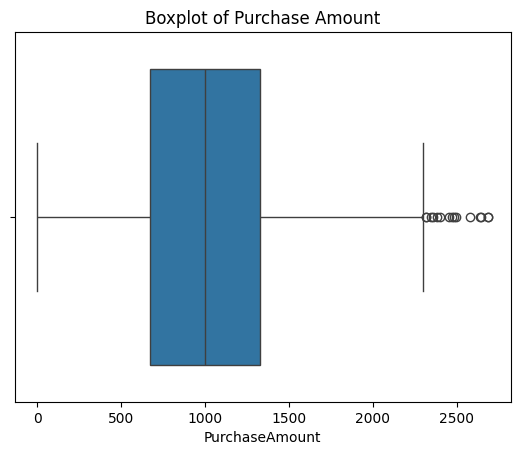

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Detect outliers using IQR
df = pd.read_csv("/content/customer_behavior.csv")
Q1 = df["PurchaseAmount"].quantile(0.25)
Q3 = df["PurchaseAmount"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outliers = df[(df["PurchaseAmount"] < lower_bound) | (df["PurchaseAmount"] > upper_bound)]
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of outliers:", len(outliers))
print(outliers[["CustomerID", "PurchaseAmount"]])

# Visualize outliers using a boxplot
sns.boxplot(x=df["PurchaseAmount"])
plt.title("Boxplot of Purchase Amount")
plt.show()

**Interpretation**:*Values below the lower bound or above the upper bound are potential outliers. Outliers are not necessarily errors; they may represent genuine high-value or low-value purchases.* *In this data 15 outliers exists*

**Question No:3**
*Skewness and Kurtosis of PurchaseAmount Distribution*

Skewness: 0.10609189374631554
Excess Kurtosis: -0.2615105545319705


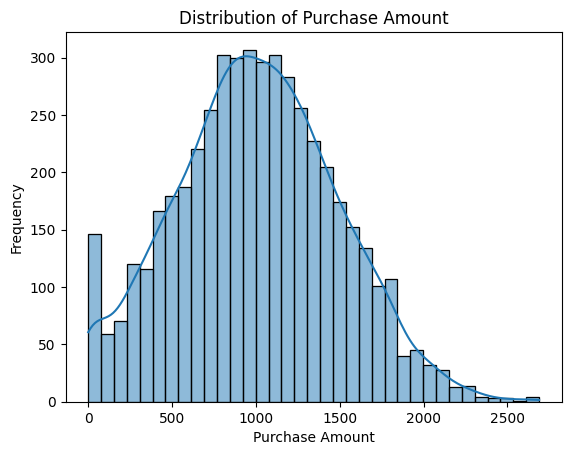

In [ ]:
#Skewness and kurtosis
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
df = pd.read_csv("/content/customer_behavior.csv")
purchase = df["PurchaseAmount"]
skewness = purchase.skew()
kurtosis = purchase.kurt()
print("Skewness:", skewness)
print("Excess Kurtosis:", kurtosis)
# Plot the distribution
sns.histplot(purchase, kde=True)
plt.title("Distribution of Purchase Amount")
plt.xlabel("Purchase Amount")
plt.ylabel("Frequency")
plt.show()

**Interpretation:** *PurchaseAmount distribution is nearly symmetrical distribution with slight right skew.Slightly flatter shape than normal distribution.Slightly platykurtic.No strong skewness or excess kurtosis based on the values alone.*

**Question NO:4**
*Significant difference in spending between male and female customers*

In [ ]:
#Compare spending by gender
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
df = pd.read_csv("/content/customer_behavior.csv")
male = df.loc[df["Gender"].str.strip().str.lower() == "male","PurchaseAmount"].dropna()
female = df.loc[ df["Gender"].str.strip().str.lower() == "female","PurchaseAmount"].dropna()
print("Male average spending:", male.mean())
print("Female average spending:", female.mean())
t_statistic, p_value = stats.ttest_ind( male, female, equal_var=False)
print("T-statistic:", t_statistic)
print("P-value:", p_value)
if p_value < 0.05:
    print("There is a statistically significant difference.")
else:
    print("There is no statistically significant difference.")

Male average spending: 1019.1766093880973
Female average spending: 987.8720464135021
T-statistic: 2.234798912073049
P-value: 0.025476849797238143
There is a statistically significant difference.


**Interpretation:**
*At a 5% significance level, a p-value below 0.05 indicates evidence of a difference in average spending.This test assumes independent customer observations and is most reliable when each group has a reasonably well-behaved sampling distribution.*

**Question No:5** *Relationship between product Category and customerchurn*

Contingency Table:
Churn             No  Yes
ProductCategory          
Electronics      785  541
Fashion          839  607
Grocery          855  604
Chi-square Statistic: 0.3960436652673918
Degrees of Freedom: 2
P-value: 0.8203519424988512
No statistically significant association was found.


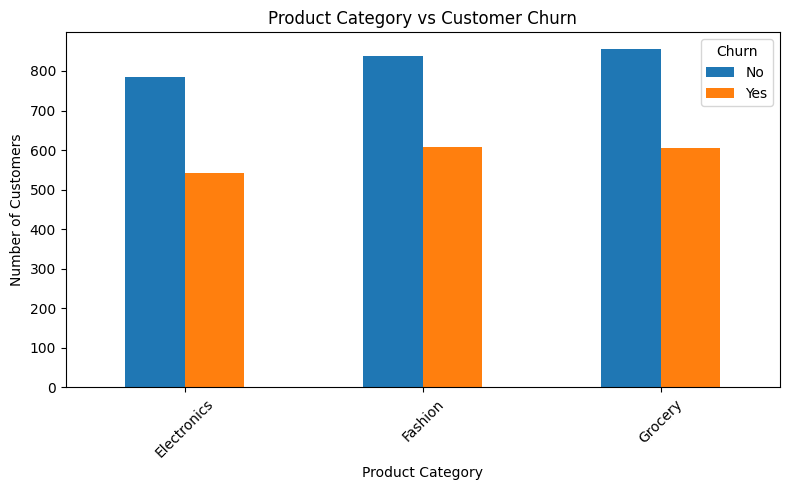

In [ ]:
#Product category and customer churn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
df = pd.read_csv("/content/customer_behavior.csv")
contingency_table = pd.crosstab(df["ProductCategory"],df["Churn"])
print("Contingency Table:")
print(contingency_table)
chi2, p_value, dof, expected = stats.chi2_contingency( contingency_table)
print("Chi-square Statistic:", chi2)
print("Degrees of Freedom:", dof)
print("P-value:", p_value)
if p_value < 0.05:
    print("ProductCategory and Churn are associated.")
else:
    print("No statistically significant association was found.")
# Visualize churn counts by category
contingency_table.plot(kind="bar", figsize=(8, 5))
plt.title("Product Category vs Customer Churn")
plt.xlabel("Product Category")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Interpretation:** *No relationship between Product Category and Customer Churn.*

 ** Question No:6** *Variation of PurchaseAmount across different regions*

Average spending by region:
Region
East     1009.946017
North    1013.017952
South     997.603877
West      995.247327
Name: PurchaseAmount, dtype: float64
F-statistic: 0.38966786354806704
P-value: 0.760452802731563
No significant difference across regions was found.


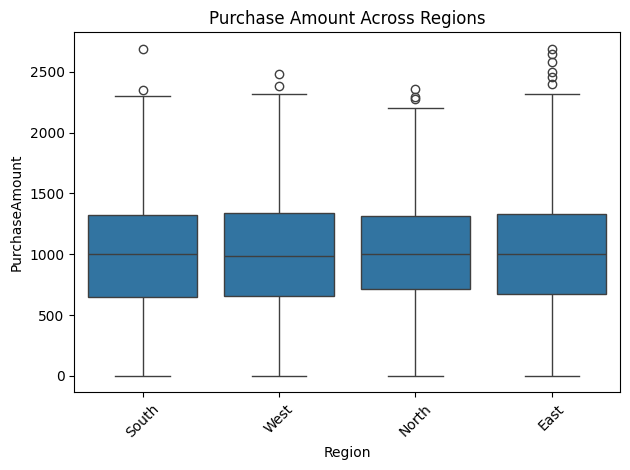

In [1]:
#Compare purchase amounts across regions
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
df = pd.read_csv("/content/customer_behavior.csv")
region_groups = [group["PurchaseAmount"].dropna().values
    for name, group in df.groupby("Region")
    if len(group["PurchaseAmount"].dropna()) > 0]
print("Average spending by region:")
print(df.groupby("Region")["PurchaseAmount"].mean())
f_statistic, p_value = stats.f_oneway(*region_groups)
print("F-statistic:", f_statistic)
print("P-value:", p_value)
if p_value < 0.05:
    print("Spending differs significantly across regions.")
else:
    print("No significant difference across regions was found.")

# Visualization
sns.boxplot(data=df, x="Region", y="PurchaseAmount")
plt.title("Purchase Amount Across Regions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Interpretation**: PurchaseAmount does not vary across differnt regions.

**Question NO:7**
*Which email campaign (A or B) performed better in terms of average PurchaseAmoun*t?

In [2]:
import pandas as pd
import numpy as np
from scipy import stats

# Load the dataset
df =df = pd.read_csv("/content/customer_behavior.csv")

# Separate customers into Campaign A and Campaign B
campaign_a = df.loc[ df["CampaignGroup"] == "A", "PurchaseAmount"].dropna()
campaign_b = df.loc[df["CampaignGroup"] == "B", "PurchaseAmount"].dropna()
# Calculate sample sizes and average purchase amounts
n_a = len(campaign_a)
n_b = len(campaign_b)
mean_a = campaign_a.mean()
mean_b = campaign_b.mean()
print("Campaign A")
print("Sample Size:", n_a)
print("Average Purchase Amount:", mean_a)
print("\nCampaign B")
print("Sample Size:", n_b)
print("Average Purchase Amount:", mean_b)
# Define hypotheses
# H0: Mean spending is equal for both campaigns
# H1: Mean spending differs between the campaigns
# Perform A/B test using Welch's t-test
t_stat, p_value = stats.ttest_ind(campaign_a,campaign_b,equal_var=False,alternative="two-sided")
print("\nA/B Testing Results")
print("T-statistic:", t_stat)
print("P-value:", p_value)
# Significance level
alpha = 0.05
if p_value < alpha:
    print("Reject the null hypothesis.")
    print("There is a statistically significant difference "
          "in average spending between campaigns.")
    if mean_a > mean_b:
        print("Campaign A performed better in average spending.")
    elif mean_b > mean_a:
        print("Campaign B performed better in average spending.")
    else:
        print("The average spending values are equal.")
else:
    print("Fail to reject the null hypothesis.")
    print("There is no statistically significant difference "
          "in average spending between campaigns.")

# Calculate the difference in average spending
print("\nDifference (A - B):", mean_a - mean_b)


Campaign A
Sample Size: 2350
Average Purchase Amount: 1011.9455872340425

Campaign B
Sample Size: 2318
Average Purchase Amount: 994.3399654874893

A/B Testing Results
T-statistic: 1.2430861943551852
P-value: 0.21389858277292212
Fail to reject the null hypothesis.
There is no statistically significant difference in average spending between campaigns.

Difference (A - B): 17.605621746553197


**Interpretation**: *Average PurchaseAmount is equal for both campaigns*

**Question NO:8**
*Can we assume PurchaseAmount follows a normal distribution?*

Shapiro-Wilk Statistic: 0.9949505740555428
P-value: 5.74412779948217e-12
Reject normality: evidence against a normal distribution.


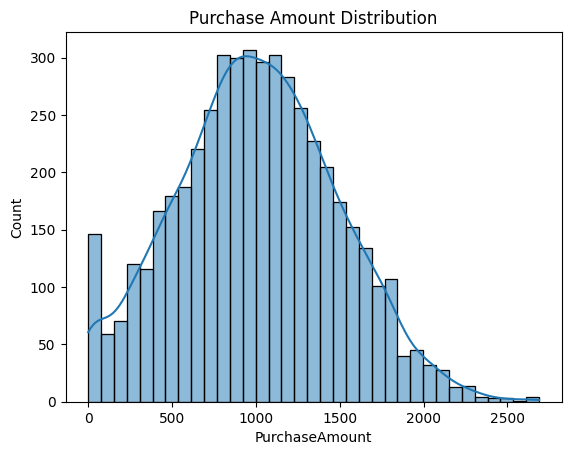

In [3]:
 #Test for normality
import pandas as pd
import numpy as np
from scipy import stats
# Load the dataset
df =df = pd.read_csv("/content/customer_behavior.csv")
purchase = df["PurchaseAmount"].dropna()
# Shapiro-Wilk accepts up to 5000 observations
sample = purchase.sample(n=min(len(purchase), 5000), random_state=42)
statistic, p_value = stats.shapiro(sample)
print("Shapiro-Wilk Statistic:", statistic)
print("P-value:", p_value)
if p_value < 0.05:
    print("Reject normality: evidence against a normal distribution.")
else:
    print("Fail to reject normality: insufficient evidence against normality.")
# Histogram
sns.histplot(purchase, kde=True)
plt.title("Purchase Amount Distribution")
plt.show()



**Interpretation**:*PurchaseAmount does not follow normal distribution.*

**Question NO:9**
*What insights can we gain by applying the Central Limit Theorem?*

Original population mean: 1003.9506701030928
Mean of sample means: 1002.79177
Standard deviation of sample means: 87.3437481690895


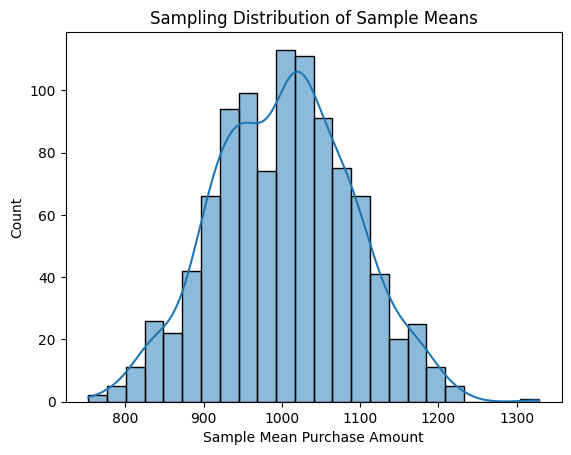

In [8]:
#Demonstrate the Central Limit Theorem
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Load the dataset
df = pd.read_csv("/content/customer_behavior.csv")
purchase = df["PurchaseAmount"].dropna().to_numpy()
if len(purchase) < 2:
    print("At least two observations are required.")
else:
    np.random.seed(42)
    sample_size = min(30, len(purchase))
    number_of_samples = 1000
    sample_means = [np.mean(np.random.choice(purchase, size=sample_size, replace=True))
                    for _ in range(number_of_samples)]
    print("Original population mean:", np.mean(purchase))
    print("Mean of sample means:", np.mean(sample_means))
    print("Standard deviation of sample means:", np.std(sample_means, ddof=1))
    sns.histplot(sample_means, kde=True)
    plt.title("Sampling Distribution of Sample Means")
    plt.xlabel("Sample Mean Purchase Amount")
    plt.show()

**Interpretation**:

The mean of the sample means should be close to the overall dataset mean.The sampling distribution of the means may look approximately normal as the sample size increases.
The standard deviation of sample means is called the standard error; under suitable conditions, it is approximately the population standard deviation divided by the square root of the sample size.This simulation samples with replacement from the observed dataset. It demonstrates the CLT relative to that dataset; it does not guarantee that the dataset perfectly represents all customers.

**Question NO:10**
*What is the 95% confidence interval for the average PurchaseAmount?*

In [9]:
#95% confidence interval
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
# Load the dataset
df = pd.read_csv("/content/customer_behavior.csv")
purchase = df["PurchaseAmount"].dropna()
n = len(purchase)
mean_value = purchase.mean()
std_dev = purchase.std(ddof=1)
standard_error = std_dev / np.sqrt(n)
confidence_level = 0.95
degrees_of_freedom = n - 1
t_critical = stats.t.ppf((1 + confidence_level) / 2, degrees_of_freedom)
margin_of_error = t_critical * standard_error
lower_ci = mean_value - margin_of_error
upper_ci = mean_value + margin_of_error
print("Sample Size:", n)
print("Mean Purchase Amount:", mean_value)
print("Standard Error:", standard_error)
print("95% Confidence Interval:",
      (lower_ci, upper_ci))

Sample Size: 4850
Mean Purchase Amount: 1003.9506701030928
Standard Error: 6.922740985370979
95% Confidence Interval: (np.float64(990.3789594609216), np.float64(1017.522380745264))


**Interpretation:**
*The resulting lower and upper values give the 95% confidence interval for the average purchase amount. In repeated sampling under the method's assumptions, 95% of intervals constructed this way would contain the true population mean.*